## Initial Data Inspection

In [23]:
# Imports

import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict

print("Imports successful")

Imports successful


## Checking Paths

In [ ]:
# Checking for correct path

import os
print(os.getcwd())

from pathlib import Path

DATA_DIR = Path("data/raw/BraTS2020_training_data")

print("Exists?", DATA_DIR.exists())
print("Contents:")
for item in DATA_DIR.iterdir():
    print(item)

c:\dev\projects\CNN-Segmentation
Does path exist? True
Contents:
data\raw\BraTS2020_training_data\meta_data.csv
data\raw\BraTS2020_training_data\name_mapping.csv
data\raw\BraTS2020_training_data\survival_info.csv
data\raw\BraTS2020_training_data\volume_100_slice_0.h5
data\raw\BraTS2020_training_data\volume_100_slice_1.h5
data\raw\BraTS2020_training_data\volume_100_slice_10.h5
data\raw\BraTS2020_training_data\volume_100_slice_100.h5
data\raw\BraTS2020_training_data\volume_100_slice_101.h5
data\raw\BraTS2020_training_data\volume_100_slice_102.h5
data\raw\BraTS2020_training_data\volume_100_slice_103.h5
data\raw\BraTS2020_training_data\volume_100_slice_104.h5
data\raw\BraTS2020_training_data\volume_100_slice_105.h5
data\raw\BraTS2020_training_data\volume_100_slice_106.h5
data\raw\BraTS2020_training_data\volume_100_slice_107.h5
data\raw\BraTS2020_training_data\volume_100_slice_108.h5
data\raw\BraTS2020_training_data\volume_100_slice_109.h5
data\raw\BraTS2020_training_data\volume_100_slice_1

## Inspecting One Sample File

In [ ]:
# Determining what each .h5 file contains 
# Contains image (240, 240, 4) = means one 2d MRI slice with 4 channels
# Contains mask (240, 240, 3) = one 2d mask with 3 channels/regions

import h5py
from pathlib import Path

DATA_DIR = Path("data/raw/BraTS2020_training_data")
h5_files = sorted(DATA_DIR.glob("*.h5"))

sample_file = h5_files[0]
print("Sample file:", sample_file.name)

with h5py.File(sample_file, "r") as f:
    print("Keys:")
    for key in f.keys():
        print(key, f[key].shape)

Sample file: volume_100_slice_0.h5
Keys:
image (240, 240, 4)
mask (240, 240, 3)


## Visualizing One Sample

Total volumes: 369
Using volume: volume_100
Sample file: volume_100_slice_77.h5
Image shape: (240, 240, 4)
Mask shape: (240, 240, 3)


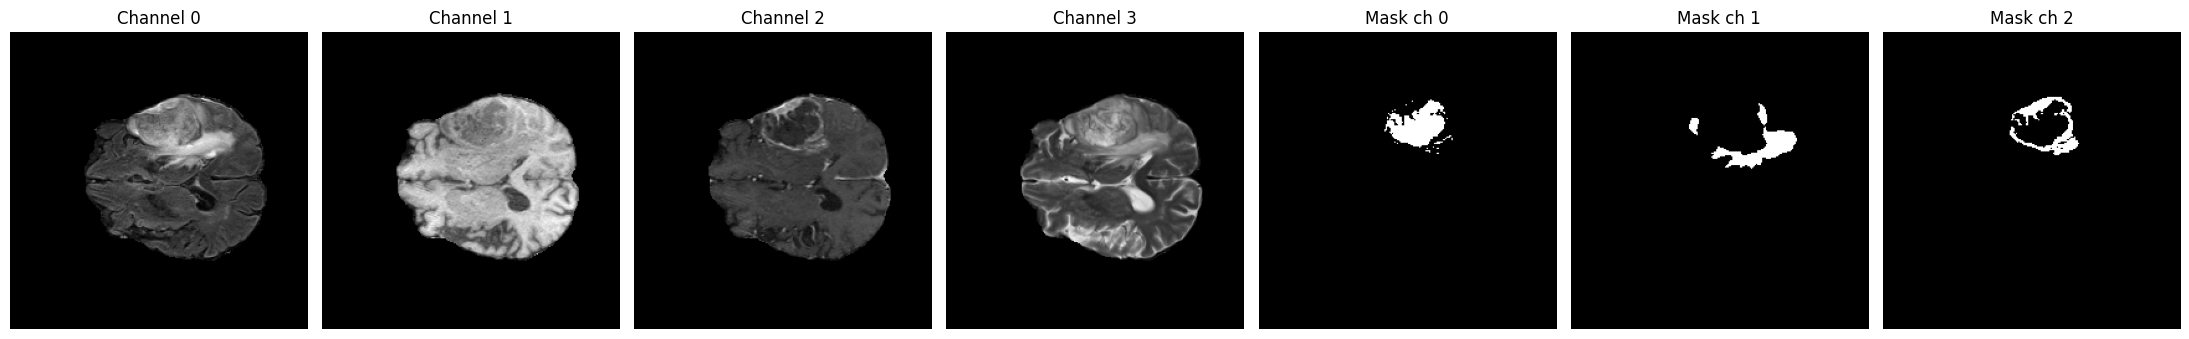

Binary mask unique values: [0 1]


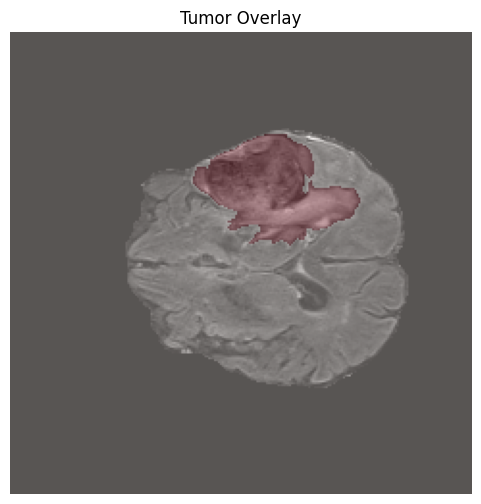

In [ ]:
# Grouping the files by volume forfuture splits
# Avoids mistakes by individual slices appearing where they shouldnt
volume_to_files = defaultdict(list)

for f in h5_files:
    parts = f.stem.split("_")  
    volume_id = f"{parts[0]}_{parts[1]}"
    volume_to_files[volume_id].append(f)

print("Total volumes:", len(volume_to_files))


# Sorting the slices within each volume
for volume_id in volume_to_files:
    volume_to_files[volume_id] = sorted(
        volume_to_files[volume_id],
        key=lambda x: int(x.stem.split("_")[-1])  
    )
# Picking an example sample 
# (starting with the middle slice of the first volume)
example_volume = list(volume_to_files.keys())[0]
volume_files = volume_to_files[example_volume]

sample_file = volume_files[len(volume_files) // 2]

print("Using volume:", example_volume)
print("Sample file:", sample_file.name)


# Loading the image and mask 
with h5py.File(sample_file, "r") as f:
    image = f["image"][:]   
    mask = f["mask"][:]     

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)


# Visualization 
fig, axes = plt.subplots(1, 7, figsize=(22, 5))

# 4 MRI channels
for i in range(4):
    axes[i].imshow(
        image[:, :, i],
        cmap="gray",
        vmin=image[:, :, i].min(),
        vmax=image[:, :, i].max()
    )
    axes[i].set_title(f"Channel {i}")
    axes[i].axis("off")

# 3 mask channels
for i in range(3):
    axes[4 + i].imshow(mask[:, :, i], cmap="gray")
    axes[4 + i].set_title(f"Mask ch {i}")
    axes[4 + i].axis("off")

plt.tight_layout()
plt.show()


# Creating a binary whole-tumor mask 
binary_mask = (mask.sum(axis=-1) > 0).astype("uint8")

print("Binary mask unique values:", np.unique(binary_mask))


#  Overlaying tumor on MRI
plt.figure(figsize=(6, 6))
plt.imshow(image[:, :, 0], cmap="gray",
           vmin=image[:, :, 0].min(),
           vmax=image[:, :, 0].max())
plt.imshow(binary_mask, cmap="Reds", alpha=0.35)
plt.title("Tumor Overlay")
plt.axis("off")
plt.show()